# تسک ۰۰۳ — مدل‌سازی و خروجی نهایی مشتری‌ها

اینجا هر پنج مرحله را اجرا می‌کنم و آخر کار یک CSV با **یک ردیف برای هر شناسهٔ مشتری موجود در فایل** می‌سازم. مشتری خفته، تازه‌وارد و فاقد خرید مثبت هم از فهرست ناپدید نمی‌شود؛ اگر سابقه برای امتیاز کافی نباشد، به‌جای احتمال ساختگی وضعیتش را مشخص می‌کنم.

هر ۵۰ سؤال فایل اولیه حفظ شده‌اند. هر جا متن سؤال با قرارداد جدید فرق دارد، در جواب توضیح داده‌ام. هدف اصلی `churn_target` است: توقف خرید یا افت قابل‌توجه/فاصلهٔ طولانی طبق تعریف مرحلهٔ قبل. الگوریتم‌ها اجرا می‌شوند، ولی اجراشدن مساوی خوب‌بودن نتیجه نیست.

**دو زمان را قاطی نمی‌کنم:** ارزیابی تاریخی در پایان اوت ۲۰۱۱ انجام می‌شود و رفتار صد روز بعد برای سنجش در دسترس است. CSV اصلی برای آخرین زمان موجود فایل، ۹ دسامبر ۲۰۱۱ است؛ در آن مرحله تاریخچه را تا همان لحظه دوباره می‌سازم و آیندهٔ پس از آن را ندارم. پس امتیاز آخر فایل، ارزیابی آیندهٔ اثبات‌شده نیست و تغییر فصل/طول سابقه محدودیت انتقال مدل است.

فروشگاه و تیم بازاریابی سناریوی آموزشی‌اند. ایدهٔ تقسیم مسئله و نوع روش‌ها از خودم بوده و برای انتخاب الگوریتم مشخص از هوش مصنوعی هم مشورت گرفته‌ام. نتیجهٔ کمپین واقعی، علت قطعی ریزش یا سود خالص را ادعا نمی‌کنم.

## محیط و فایل‌ها

اینجا از خروجی واقعی تسک ۰۰۲ در `task-002/outputs` استفاده می‌کنم. ریشهٔ ریپو از پوشهٔ جاری یا والدهای آن پیدا می‌شود؛ اجرا از ریشهٔ پروژه یا خود task-003 هر دو ممکن است. خروجی‌های این مرحله در `task-003/outputs` ذخیره می‌شوند.

کتابخانه‌ها باید در محیط مجازی همین ریپو یعنی `.venv` نصب باشند. در VS Code کرنل همین محیط را انتخاب می‌کنم. فهرست وابستگی‌ها در `requirements.txt` ریشهٔ پروژه است؛ نصب خودکار داخل نوت‌بوک انجام نمی‌دهم. اگر از پوشه‌ای خارج از پروژه اجرا کنم، `PROJECT_ROOT_OVERRIDE` را به ریشهٔ ریپو تنظیم می‌کنم.


In [1]:
from pathlib import Path
import sys, json, pickle, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, silhouette_score, adjusted_rand_score, mean_absolute_error
from scipy.stats import spearmanr
from mlxtend.frequent_patterns import fpgrowth, association_rules
from lifetimes import BetaGeoFitter, GammaGammaFitter
import dill
SEED=42
# ریشهٔ پروژه را از پوشهٔ اجرای ژوپیتر یا والدهایش پیدا می‌کنم.
# اجرا از ریشهٔ ریپو و از task-003 هر دو پشتیبانی می‌شوند.
PROJECT_ROOT_OVERRIDE = None
if PROJECT_ROOT_OVERRIDE is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    possible_roots = [here, *here.parents]
    PROJECT_ROOT = next((d for d in possible_roots
        if (d / 'task-002' / 'outputs' / 'prepared_manifest.json').is_file()
        and (d / 'task-003' / 'task003_modeling_complete.ipynb').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('ریشهٔ ریپو پیدا نشد؛ PROJECT_ROOT_OVERRIDE را تنظیم کنید.')
BASE = PROJECT_ROOT / 'task-002' / 'outputs'
OUT = PROJECT_ROOT / 'task-003' / 'outputs'
required_inputs = [
    'prepared_manifest.json', 'churn_customers.csv', 'clustering_customers.csv',
    'anomaly_customers.csv', 'transactions_clean.csv', 'basket_matrix_train.csv',
    'basket_matrix_test.csv', 'baskets_customer_train.csv', 'clv_calibration.csv',
    'clv_gamma_calibration.csv', 'clv_holdout.csv',
]
missing_files = [name for name in required_inputs if not (BASE / name).is_file()]
if missing_files:
    raise FileNotFoundError('فایل‌های آماده‌سازی موجود نیستند: ' + ', '.join(missing_files))
OUT.mkdir(parents=True, exist_ok=True)
print('Python executable:', sys.executable)
print('Project root:', PROJECT_ROOT)
print('Task 002 inputs:', BASE)
print('Task 003 outputs:', OUT)
manifest=json.loads((BASE/'prepared_manifest.json').read_text(encoding='utf-8'))
FEATURES=manifest['features']['cart']; KF=manifest['features']['clustering']; AF=manifest['features']['anomaly']
TARGET='churn_target'; HORIZON=100
churn=pd.read_csv(BASE/'churn_customers.csv')
cluster_raw=pd.read_csv(BASE/'clustering_customers.csv')
anomaly=pd.read_csv(BASE/'anomaly_customers.csv')
transactions=pd.read_csv(BASE/'transactions_clean.csv',dtype={'InvoiceNo':str,'StockCode':str})
transactions['InvoiceDate']=pd.to_datetime(transactions['InvoiceDate'])
obs_cut=pd.Timestamp(manifest['performance']['start'])
raw_end=transactions.InvoiceDate.max()
LABELS=['hard_churn','churn_target','churn_target_no_gap','soft_decline','decline_flag','gap_signal']
train=churn['split'].eq('train'); val=churn['split'].eq('validation'); test=churn['split'].eq('test')
X=churn[FEATURES]; y=churn[TARGET].astype(int)
Xtr,Xv,Xte=X.loc[train],X.loc[val],X.loc[test]
ytr,yv,yte=y.loc[train],y.loc[val],y.loc[test]
cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
RISK_LABELS=['بسیار کم','کم','متوسط','زیاد','بسیار زیاد']
# آستانه‌ها ثابت و نمایشی‌اند؛ مشتری‌های هم‌امتیاز همیشه هم‌سطح‌اند.
RISK_EDGES=[0,.2,.4,.6,.8,1.000001]
def risk_tier(p): return pd.cut(np.asarray(p),RISK_EDGES,labels=RISK_LABELS,right=False,include_lowest=True)
print('Prepared source:',BASE.resolve(),'| reference:',obs_cut,'| latest:',raw_end)
display(churn.groupby('split')[TARGET].agg(customers='size',target_rate='mean'))

C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\.venv\Lib\site-packages\lifetimes\utils.py:9: Pandas4Warning: The 'mode.chained_assignment' option is deprecated. It has had no effect since pandas 3.0, which removed the SettingWithCopyWarning it controlled. Chained assignment now emits a ChainedAssignmentError warning instead; use warnings.filterwarnings with category=ChainedAssignmentError to silence or escalate it. This option will be removed in pandas 4.0.
  pd.options.mode.chained_assignment = None


Python executable: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\.venv\Scripts\python.exe
Project root: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks
Task 002 inputs: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\task-002\outputs
Task 003 outputs: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\task-003\outputs


Prepared source: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\task-002\outputs | reference: 2011-09-01 00:00:00 | latest: 2011-12-09 12:50:00


,customers,target_rate
split,,
test,461,0.494577
train,1378,0.494194
validation,459,0.494553


## سوال ۱

داده‌کاوی را تعریف کنید و تفاوت آن با یادگیری ماشین چیست؟

اینجا داده‌کاوی را مسیر تبدیل داده به یک تصمیم می‌بینم و یادگیری ماشین را یکی از ابزارهایش. هدف من فقط نمرهٔ مدل نیست؛ فهرست مشتری باید قابل‌فهم و قابل‌پیگیری باشد.

## سوال ۲

انواع یادگیری را مقایسه کنید: Supervised، Unsupervised، Semi-Supervised و Reinforcement.

CART نظارت‌شده است چون برچسب عملیاتی داریم؛ K-Means، Isolation Forest و قواعد خرید برچسب آماده ندارند. یادگیری نیمه‌نظارتی و تقویتی را وارد این تحویل نمی‌کنم چون نیاز روشن و دادهٔ اقدام ندارم.

## سوال ۳

پنج نوع مسئلهٔ داده‌کاوی را با مثال تعریف کنید.

طبقه‌بندی کلاس را پیش‌بینی می‌کند، رگرسیون مقدار را، خوشه‌بندی ساختار را، قواعد انجمنی همراهی را و تشخیص ناهنجاری رفتار متفاوت را. BG/NBD و Gamma-Gamma مدل احتمالی خرید و مبلغ‌اند؛ صرفاً رگرسیون معمولی نیستند.

## سوال ۴

مسئلهٔ فروشگاه آنلاین از چه نوعی است و چرا یک مسئلهٔ واحد نیست؟

شناخت تیپ مشتری، خطر ریزش، محصول مرتبط و ارزش آینده سؤال‌های جدا هستند. طرح ترکیبی برای پاسخ به آن‌هاست؛ هیچ مدل به‌تنهایی علت ریزش یا اثر پیشنهاد را ثابت نمی‌کند.

## سوال ۵

متغیر هدف هر مرحله چیست؟

هدف اصلی برچسب ترکیبی churn_target است. توقف خرید را هم جداگانه مقایسه می‌کنم. خوشه و ناهنجاری برچسب حقیقت ندارند؛ frequency/recency/T و مبلغ تکراری خلاصه‌های ورودی مدل خریدند.

## سوال ۶

هر مرحله به کدام نمای داده نیاز دارد؟

از نمای مشتری برای خوشه و خطر، نمای ناهنجاری مشتری، سبد فاکتور و نمای روز خرید برای CLV استفاده می‌کنم. واحدها متفاوت‌اند و یکی را به جای دیگری نمی‌گذارم.

## سوال ۷

چرا ترتیب پنج مرحله مهم است؟

اول کیفیت و ورودی را روشن می‌کنم، بعد تیپ و خطر و پیشنهاد و ارزش را کنار هم می‌گذارم. مشتری غیرعادی را حذف نمی‌کنم و لازم نیست همهٔ مراحل خروجی مستقیم همدیگر باشند.

## سوال ۸

اگر برچسب ریزش حذف شود، مسئله به چه نوعی تبدیل می‌شود؟

بدون برچسب هنوز می‌توانم گروه‌بندی و رتبه‌بندی توصیفی داشته باشم، ولی دیگر ارزیابی طبقه‌بند نسبت به همان تعریف ریزش را ندارم.

## سوال ۹

پنج الگوریتم نهایی را با نوع و نقش هر کدام معرفی کنید.

انتخاب‌های اولیه Isolation Forest، K-Means، CART، FP-Growth و BG/NBD همراه Gamma-Gamma هستند. انتخاب الگوریتم با مشورت دقیق‌تر شده، اما نتیجهٔ اجرا باید فایدهٔ آن را نشان بدهد.

## سوال ۱۰

چرا برای ناهنجاری Isolation Forest انتخاب شد؟

Isolation Forest را برای علامت رفتار متفاوت انتخاب کردم؛ بدون برچسب کار می‌کند و فرض نرمال لازم ندارد. قواعد ساده هم کنار آن می‌مانند. هم‌پوشانی قواعد را بازبینی انسانی واقعی نام نمی‌گذارم.

## سوال ۱۱

چرا برای بخش‌بندی K-Means انتخاب شد؟

K-Means شروع ساده و قابل‌توضیحی برای پروفایل مشتری است. مقیاس، چولگی، k و پایداری را بررسی می‌کنم؛ آماده‌سازی به‌تنهایی شکل کروی خوشه را تضمین نمی‌کند.

## سوال ۱۲

چرا برای پیش‌بینی ریزش CART انتخاب شد؟

CART به خاطر قواعد خوانا انتخاب اولیه است. با CV تنظیم و با لجستیک مقایسه می‌شود. تفسیرپذیری را بهانهٔ پنهان‌کردن عملکرد ضعیف نمی‌کنم.

## سوال ۱۳

چرا برای قواعد سبد خرید FP-Growth انتخاب شد؟

فاکتور ساختار سبد دارد و FP-Growth قواعد خوانا می‌دهد. انتخاب آن به معنی اثبات بهترین پیشنهاد حفظ مشتری نیست؛ فقط محصول مرتبط پیدا می‌کنم.

## سوال ۱۴

چرا برای ارزش طول عمر BG/NBD و Gamma-Gamma انتخاب شدند؟

BG/NBD برای خرید غیرقراردادی و Gamma-Gamma برای مبلغ خرید مناسبِ بررسی‌اند. خریدهای یک روز یک رویدادند. خروجی من درآمد موردانتظار صد روز آینده است، نه سود خالص یا کل عمر نامحدود.

## سوال ۱۵

کدام الگوریتم‌ها Explainable هستند؟

درخت قواعد روشن و قواعد خرید همراهی روشن دارند. خوشه با پروفایل توضیح داده می‌شود و IF فقط امتیاز متفاوت‌بودن می‌دهد. احتمال مدل خرید هم تحت فرض‌های خودش است.

## سوال ۱۶

چرا تفسیرپذیری در نگه‌داشت مشتری مهم است؟

تیم فرضی بازاریابی باید دلیل اولویت را بفهمد. قاعدهٔ درخت رابطهٔ پیش‌بینی را توضیح می‌دهد؛ نمی‌گوید با تغییر آن ویژگی حتماً مشتری حفظ می‌شود.

## سوال ۱۷

اگر Performance و Explainability تضاد داشته باشند، کدام مهم‌تر است؟

خروجی ساده و قابل‌فهم را ترجیح می‌دهم به شرط گزارش صادقانهٔ کیفیت. اگر baseline بهتر باشد، این محدودیت باید در گزارش و فایل نهایی مشخص باشد.

## سوال ۱۸

پیش‌بینی کنید کدام مدل بهترین عملکرد و کدام بیشترین ریسک بیش‌برازش را دارد.

قبل از اجرا انتظار قطعی ندارم. درخت عمیق ممکن است بیش‌برازش کند؛ خوشه به آماده‌سازی حساس است؛ قواعد به حجم سبد و CLV به فرض خرید و فصل. هیچ‌کدام از الان موفق فرض نمی‌شوند.

## سوال ۱۹

چرا داده را به Train و Test تقسیم می‌کنیم و چرا ترتیب زمانی مهم است؟

پنجرهٔ مشاهده و رفتار بعدی زمان‌بندی ویژگی و برچسب را تعیین می‌کنند. split ثبت‌شدهٔ مشتری‌ها، آموزش/اعتبارسنجی/آزمون جدا می‌سازد؛ این آزمون آیندهٔ زمانی نیست. کل فایل قبلاً اکتشاف شده و آزمون کاملاً بکر از ابتدای پروژه نیست.

## سوال ۲۰

قرارداد ارزیابی و آستانه‌های Go/No-Go را بازخوانی کنید.

معیارها با خروجی انتخاب می‌شوند: PR-AUC و بالای فهرست، کالیبراسیون، پروفایل و پایداری خوشه، Lift قواعد و خطای خرید آینده. آستانهٔ دلخواه را قانون موفقیت نمی‌نامم و نتیجهٔ آزمون را برای تنظیم مصرف نمی‌کنم.

## سوال ۲۱

تقسیم ۸۰/۲۰ طبقه‌بندی‌شده را پیاده‌سازی کنید و توزیع برچسب را مقایسه کنید.

متن اصلی سؤال ۸۰/۲۰ بود؛ برای هماهنگی با تسک اصلاح‌شده تقسیم ۶۰/۲۰/۲۰ را دوباره نمی‌سازم و همان split را می‌خوانم.

In [2]:
assert churn.CustomerID.is_unique
assert set(churn.split)=={'train','validation','test'}
assert set(FEATURES).isdisjoint(LABELS+['split','CustomerID'])
assert set(churn.loc[train,'CustomerID']).isdisjoint(churn.loc[val|test,'CustomerID'])
display(churn.groupby('split')[TARGET].agg(n='size',positives='sum',rate='mean'))

,n,positives,rate
split,,,
test,461,228,0.494577
train,1378,681,0.494194
validation,459,227,0.494553


## سوال ۲۲

چرا random_state و Stratification اهمیت دارند؟

بذر ثابت اجرای تقسیم را قابل‌تکرار می‌کند و طبقه‌بندی‌شده بودن کمک می‌کند نسبت کلاس‌ها نزدیک بماند. انتخاب چند بذر برای پیدا کردن نتیجهٔ بهتر مجاز نیست؛ split مرحلهٔ قبل را ثابت نگه می‌دارم.

## سوال ۲۳

Cross Validation چیست و چرا 5-Fold انتخاب شد؟

پنج Fold روی آموزش کمک می‌کند تنظیم مدل به یک برش کوچک وابسته نباشد. اعتبارسنجی و آزمون نهایی در این CV وارد نمی‌شوند.

## سوال ۲۴

5-Fold Cross Validation را اجرا کنید و میانگین و انحراف معیار PR-AUC را گزارش کنید.

اینجا یک درخت ساده را فقط روی آموزش با ۵-Fold می‌سنجم؛ نتیجهٔ آن آزمون نهایی نیست.

In [3]:
base_tree=DecisionTreeClassifier(max_depth=4,min_samples_leaf=40,random_state=SEED)
cv_scores=cross_val_score(base_tree,Xtr,ytr,cv=cv,scoring='average_precision',n_jobs=1)
display(pd.DataFrame({'fold':range(1,6),'average_precision':cv_scores}))
print('CV mean/std:',cv_scores.mean(),cv_scores.std())

,fold,average_precision
0,1,0.654926
1,2,0.645170
2,3,0.602894
3,4,0.627150
4,5,0.627487


CV mean/std: 0.6315254913480889 0.01782665813403548


## سوال ۲۵

آزمون فشار کوهورت زمانی را اجرا کنید: آموزش روی مشتریان قدیمی و آزمون روی مشتریان جدید.

اینجا درون آموزش، مشتری‌های باسابقه‌تر را برای آموزش و جدیدترها را برای فشار تعمیم جدا می‌کنم. این تقسیم بر اساس سابقه در یک تاریخ است، نه آموزش در گذشته و آزمون در تاریخ آینده. برای تنظیم مدل اصلی از نتیجهٔ آن استفاده نمی‌کنم.

In [4]:
cut=Xtr.obs_tenure.quantile(.2)
oldmask=Xtr.obs_tenure>cut
stress=DecisionTreeClassifier(max_depth=4,min_samples_leaf=30,random_state=SEED).fit(Xtr.loc[oldmask],ytr.loc[oldmask])
stress_p=stress.predict_proba(Xtr.loc[~oldmask])[:,1]
print('Training-only newcomer stress AP:',average_precision_score(ytr.loc[~oldmask],stress_p))
print('Recency AP:',average_precision_score(ytr.loc[~oldmask],Xtr.loc[~oldmask,'obs_recency']))

Training-only newcomer stress AP: 0.7273981851252808
Recency AP: 0.6269748549803869


## سوال ۲۶

قواعد ضد نشت را چگونه رعایت کردید؟

اینجا جدایی ویژگی و برچسب و مشتری‌ها را بررسی می‌کنم. تکرارهای زمانی یک مشتری نساخته‌ام. تبدیل‌های لجستیک در Pipeline و تبدیل‌های خوشه فقط روی دادهٔ مجاز fit می‌شوند.

In [5]:
assert not X.isna().any().any()
assert not any(c.startswith(('perf_','lbl_')) for c in FEATURES)
assert set(churn.loc[val,'CustomerID']).isdisjoint(churn.loc[test,'CustomerID'])
print('Feature, label and customer split checks passed.')

Feature, label and customer split checks passed.


## سوال ۲۷

مدل Isolation Forest را در سطح مشتری آموزش دهید و فهرست بازبینی بسازید.

اینجا IF را روی مشتری‌های دارای خرید در پنجرهٔ مشاهده fit می‌کنم. امتیاز بالا یعنی متفاوت‌تر؛ نه خطای قطعی یا خطر ریزش.

In [6]:
iso=IsolationForest(n_estimators=200,contamination='auto',random_state=SEED,n_jobs=1).fit(anomaly[AF])
anomaly['anomaly_score']=-iso.score_samples(anomaly[AF])
anomaly['review_rank']=anomaly.anomaly_score.rank(ascending=False,method='first').astype(int)
display(anomaly.sort_values('review_rank').head(10))

,CustomerID,obs_invoices,obs_spend,obs_avg_basket,obs_products,cancel_rate,obs_max_line_qty,obs_max_invoice_value,return_value_share,rule_top1pct_spend,rule_big_line_qty,rule_high_return_share,rule_any,anomaly_score,review_rank
0,12346,1,77183.60,77183.600000,1,0.500000,74215,77183.60,0.500000,1,1,1,1,0.834729,1
1315,14646,40,176355.94,4408.898500,491,0.069767,1440,19150.66,0.004049,1,1,0,1,0.822118,2
1927,15749,3,44534.30,14844.766667,5,0.250000,3114,21535.90,0.340552,1,1,1,1,0.813484,3
1030,14156,35,84977.35,2427.924286,595,0.102564,1440,16774.72,0.041534,1,1,0,1,0.800478,4
1563,15098,3,39916.50,13305.500000,1,0.400000,60,38970.00,0.495899,1,0,1,1,0.794984,5
3213,18102,26,130537.23,5020.662692,54,0.071429,1008,16488.00,0.024065,1,1,0,1,0.794948,6
45,12415,13,99146.16,7626.627692,376,0.187500,600,22775.93,0.007531,1,0,0,1,0.791173,7
2850,17450,22,85610.34,3891.379091,107,0.153846,1356,13031.50,0.021382,1,1,0,1,0.789009,8
346,12931,11,32530.70,2957.336364,27,0.214286,2880,18841.48,0.188227,1,1,0,1,0.788823,9
2075,16029,46,52213.24,1135.070435,42,0.148148,2400,8142.75,0.233920,1,1,0,1,0.783217,10


## سوال ۲۸

کیفیت فهرست ناهنجاری را بدون برچسب حقیقت زمینی بسنجید (توضیح‌پذیری و پوشش).

اینجا هم‌پوشانی با قواعد ساده را می‌سنجم؛ این معیار شباهت دو روش است و دقت یا بازبینی انسانی نیست.

In [7]:
review=anomaly.nsmallest(50,'review_rank')
rule_overlap=float(review.rule_any.mean())
print('Top-50 rule overlap:',rule_overlap,'| all-customer rule share:',anomaly.rule_any.mean())

Top-50 rule overlap: 0.82 | all-customer rule share: 0.028640337654507086


## سوال ۲۹

پایداری مدل ناهنجاری را با بوت‌استرپ بسنجید.

اینجا با نمونه‌گیری مجدد با جایگذاری و بذرهای متفاوت پایداری رتبه را می‌سنجم.

In [8]:
ref=set(anomaly.nsmallest(100,'review_rank').CustomerID)
stability=[]
for b in range(3):
    sample=anomaly.sample(frac=1,replace=True,random_state=SEED+b)
    model=IsolationForest(n_estimators=200,random_state=SEED+b,n_jobs=1).fit(sample[AF])
    score=-model.score_samples(anomaly[AF])
    ids=set(anomaly.iloc[np.argsort(-score)[:100]].CustomerID)
    stability.append(len(ids&ref)/len(ids|ref))
print('Bootstrap Jaccard@100:',stability,'mean:',np.mean(stability))

Bootstrap Jaccard@100: [0.8518518518518519, 0.8691588785046729, 0.8518518518518519] mean: 0.8576208607361254


## سوال ۳۰

آیا Isolation Forest از قاعدهٔ ساده بهتر است؟

بدون برچسب یا بازبینی کسب‌وکار، بهتر بودن IF در پیدا کردن خطا را ثابت نمی‌کنم. اختلاف فهرست‌ها می‌تواند مورد مفیدی برای بررسی باشد. پرچم این مرحله کنار مشتری می‌ماند و او را حذف نمی‌کند.

## سوال ۳۱

تعداد خوشه را با Silhouette و پایداری انتخاب کنید.

اینجا k را روی بخش اعتبارسنجیِ خوشه‌بندی انتخاب می‌کنم؛ آن را Test نهایی نمی‌نامم. پایداری روی مجموعهٔ مرجع مشترک سنجیده می‌شود. گروه کوچک را فقط به خاطر کوچک‌بودن رد نمی‌کنم.

In [9]:
cltr,clv=train_test_split(cluster_raw,test_size=.2,random_state=SEED)
def fit_prep(frame):
    caps=frame[KF].quantile(.99)
    scale=StandardScaler().fit(np.log1p(frame[KF].clip(upper=caps,axis=1)))
    return caps,scale
def transform(frame,caps,scale): return scale.transform(np.log1p(frame[KF].clip(upper=caps,axis=1)))
caps,scale=fit_prep(cltr); ztr=transform(cltr,caps,scale); zv=transform(clv,caps,scale)
krows=[]
for k in range(2,7):
    km=KMeans(k,n_init=10,random_state=SEED).fit(ztr)
    ref=km.predict(zv); aris=[]
    for b in range(3):
        sub=cltr.sample(frac=1,replace=True,random_state=SEED+b)
        cap_b,sc_b=fit_prep(sub)
        bm=KMeans(k,n_init=5,random_state=SEED+b).fit(transform(sub,cap_b,sc_b))
        aris.append(adjusted_rand_score(ref,bm.predict(transform(clv,cap_b,sc_b))))
    krows.append([k,silhouette_score(zv,ref),np.mean(aris),np.bincount(km.labels_).min()/len(ztr)])
ktable=pd.DataFrame(krows,columns=['k','validation_silhouette','bootstrap_ari','min_train_share'])
pool=ktable[ktable.bootstrap_ari>=.7]
if pool.empty: pool=ktable
KBEST=int(pool.sort_values('validation_silhouette',ascending=False).iloc[0].k)
display(ktable); print('Chosen k:',KBEST)

,k,validation_silhouette,bootstrap_ari,min_train_share
0,2,0.254350,0.974021,0.406709
1,3,0.302290,0.972500,0.139088
2,4,0.287921,0.944104,0.102902
3,5,0.231665,0.897068,0.083679
4,6,0.239628,0.801560,0.045232


Chosen k: 3


## سوال ۳۲

مدل K-Means نهایی را آموزش دهید و بخش‌ها را تخصیص دهید.

بعد از انتخاب k، نسخهٔ توصیفی نهایی را روی تمام مشتری‌های دارای سابقهٔ مشاهده fit می‌کنم. این refit برای تخصیص نهایی است؛ نمرهٔ اعتبارسنجی مدل قبلی را نتیجهٔ مستقل آن نمی‌نامم.

In [10]:
caps_all,scale_all=fit_prep(cluster_raw)
km_final=KMeans(KBEST,n_init=20,random_state=SEED).fit(transform(cluster_raw,caps_all,scale_all))
profile=cluster_raw.copy(); profile['segment_id']=km_final.labels_

## سوال ۳۳

پروفایل هر بخش و اندازهٔ آن را گزارش کنید.

اینجا اسم خوشه را از پروفایل گذشته می‌سازم. اسم وفاداری یا علت ریزش را بدون شاهد قطعی نمی‌گذارم و نام هر گروه شناسه هم دارد تا تکراری نشود.

In [11]:
stats=profile.groupby('segment_id')[KF].mean()
global_m=profile.obs_spend.median()
name_map={}
for sid,row in stats.iterrows():
    if row.cancel_rate>.12: label='لغو و مرجوعی بیشتر'
    elif row.obs_invoices>=5 and row.obs_spend>global_m: label='پرتکرار و پرمبلغ'
    elif row.obs_recency>120: label='کم‌فعالیت و دور از آخرین خرید'
    else: label='خرید محدود یا سابقهٔ کوتاه'
    name_map[int(sid)]=f'{label} — گروه {sid}'
profile['segment_name']=profile.segment_id.map(name_map)
display(profile.groupby('segment_name')[KF].agg(['mean','median']).round(2))

obs_invoices        obs_spend           \
                                               mean median      mean   median   
segment_name                                                                    
لغو و مرجوعی بیشتر — گروه 1                    6.92    5.0   3573.17  1737.39   
لغو و مرجوعی بیشتر — گروه 2                    2.04    2.0   1018.15   498.15   
کم‌فعالیت و دور از آخرین خرید — گروه 0         1.44    1.0    358.36   295.70   

                                       obs_products        obs_avg_basket  \
                                               mean median           mean   
segment_name                                                                
لغو و مرجوعی بیشتر — گروه 1                   96.98   74.0         512.84   
لغو و مرجوعی بیشتر — گروه 2                   26.59   20.0         583.42   
کم‌فعالیت و دور از آخرین خرید — گروه 0        22.25   17.0         268.80   

                                               obs_tenure        obs_recency  \
                                        median       mean median        mean   
segment_name                                                                   
لغو و مرجوعی بیشتر — گروه 1             360.28     215.62  232.0       40.11   
لغو و مرجوعی بیشتر — گروه 2             307.90     169.79  181.0      114.84   
کم‌فعالیت و دور از آخرین خرید — گروه 0  207.62     149.96  154.0      121.54   

                                              cancel_rate        return_rate  \
                                       median        mean median        mean   
segment_name                                                                   
لغو و مرجوعی بیشتر — گروه 1              26.0        0.13   0.11        0.02   
لغو و مرجوعی بیشتر — گروه 2             100.0        0.44   0.50        0.14   
کم‌فعالیت و دور از آخرین خرید — گروه 0  112.0        0.00   0.00        0.00   

                                               
                                       median  
segment_name                                   
لغو و مرجوعی بیشتر — گروه 1              0.01  
لغو و مرجوعی بیشتر — گروه 2              0.09  
کم‌فعالیت و دور از آخرین خرید — گروه 0   0.00

## سوال ۳۴

پایداری خوشه‌بندی را تحلیل کنید و بخش‌ها را روی دو محور کسب‌وکاری نشان دهید.

اینجا اندازه و جای گروه‌ها را روی تازگی و مبلغ می‌بینم. دو محور فقط نمای خلاصه‌اند و ثابت نمی‌کنند خوشه‌ها در کل فضا کاملاً جدا هستند.

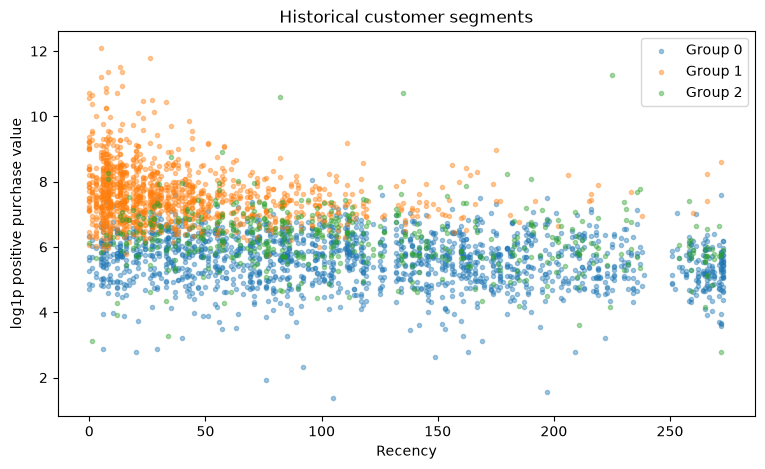

,customers
segment_id,
0,1680
1,1158
2,479


In [12]:
fig,ax=plt.subplots(figsize=(9,5))
for sid,g in profile.groupby('segment_id'): ax.scatter(g.obs_recency,np.log1p(g.obs_spend),s=9,alpha=.4,label=f'Group {sid}')
ax.set(xlabel='Recency',ylabel='log1p positive purchase value',title='Historical customer segments'); ax.legend(); plt.show()
display(profile.groupby('segment_id').size().to_frame('customers'))

## سوال ۳۵

خط پایهٔ Recency و کلاس اکثریت را بسازید و رگرسیون لجستیک را هم به‌عنوان مرجع بیفزایید.

اینجا baseline و لجستیک را فقط با آموزش می‌سازم و روی اعتبارسنجی می‌سنجم. نمرهٔ ثابت PR برابر فراوانی مثبت است؛ آن را پیش‌بینی کلاس اکثریت نمی‌نامم.

In [13]:
logit=make_pipeline(FunctionTransformer(np.log1p),StandardScaler(),LogisticRegression(max_iter=2000,random_state=SEED)).fit(Xtr,ytr)
print('Validation constant-score AP:',yv.mean())
print('Validation recency AP:',average_precision_score(yv,Xv.obs_recency))
print('Validation logistic AP:',average_precision_score(yv,logit.predict_proba(Xv)[:,1]))

Validation constant-score AP: 0.49455337690631807
Validation recency AP: 0.5662779822906295
Validation logistic AP: 0.5956640656369235


## سوال ۳۶

مدل CART را با GridSearchCV تنظیم کنید.

اینجا پارامترهای CART را با CV داخل آموزش انتخاب می‌کنم. آزمون نهایی در انتخاب پارامتر نقش ندارد.

In [14]:
grid={'max_depth':[3,4,5,7],'min_samples_leaf':[25,50,90],'class_weight':[None,'balanced']}
search=GridSearchCV(DecisionTreeClassifier(random_state=SEED),grid,scoring='average_precision',cv=cv,n_jobs=1).fit(Xtr,ytr)
best=search.best_params_
print('Best parameters:',best,'| train CV AP:',search.best_score_)

Best parameters: {'class_weight': None, 'max_depth': 4, 'min_samples_leaf': 90} | train CV AP: 0.6373907815902253


## سوال ۳۷

مدل را کالیبره کنید و منحنی کالیبراسیون را رسم کنید.

اینجا کالیبراسیون sigmoid را درون دادهٔ آموزش و با Foldهای داخلی انجام می‌دهم. اعتبارسنجی مستقل را برای نمودار می‌بینم؛ این نمونه‌ها برای برازش احتمال مصرف نشده‌اند.

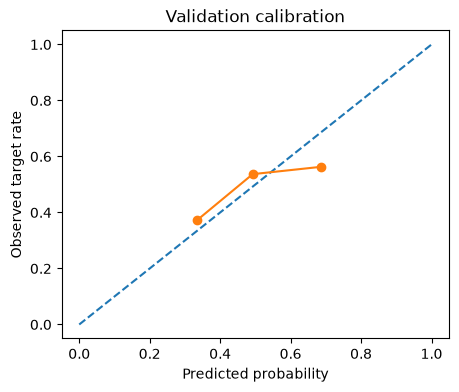

Validation Brier: 0.24404988481277748


In [15]:
cart=CalibratedClassifierCV(DecisionTreeClassifier(**best,random_state=SEED),method='sigmoid',cv=3).fit(Xtr,ytr)
pv=cart.predict_proba(Xv)[:,1]
frac,mean=calibration_curve(yv,pv,n_bins=5,strategy='uniform')
plt.figure(figsize=(5,4)); plt.plot([0,1],[0,1],'--'); plt.plot(mean,frac,'o-'); plt.xlabel('Predicted probability'); plt.ylabel('Observed target rate'); plt.title('Validation calibration'); plt.show()
print('Validation Brier:',brier_score_loss(yv,pv))
# یک درخت توضیحی جدا؛ قواعدش توضیح دقیق ensemble کالیبره‌شده نیست.
explain_tree=DecisionTreeClassifier(**best,random_state=SEED).fit(Xtr,ytr)

## سوال ۳۸

PR-AUC، ROC-AUC، Precision@k و Recall@k و Lift را گزارش کنید.

اینجا فقط یک بار مدل و baselineهای ازقبل‌تعریف‌شده را روی آزمون ثبت می‌کنم. بودجه‌ها صرفاً سناریوی ظرفیت‌اند. امتیاز average precision را با نام AP گزارش می‌کنم؛ با انتگرال ذوزنقه‌ای PR دقیقاً یکی نیست.

In [16]:
rf=RandomForestClassifier(n_estimators=200,min_samples_leaf=10,random_state=SEED,n_jobs=1).fit(Xtr,ytr)
test_predictions={'CART':cart.predict_proba(Xte)[:,1],'Logistic':logit.predict_proba(Xte)[:,1],'RandomForest_reference':rf.predict_proba(Xte)[:,1],'Recency':Xte.obs_recency.to_numpy()}
metric_rows=[]
for name,p in test_predictions.items():
    metric_rows.append([name,average_precision_score(yte,p),roc_auc_score(yte,p),brier_score_loss(yte,p) if name!='Recency' else np.nan])
test_metrics=pd.DataFrame(metric_rows,columns=['model','test_AP','test_ROC_AUC','test_Brier'])
display(test_metrics)
def budget_metrics(p,truth,k):
    truth=np.asarray(truth); k=max(1,min(k,len(truth)))
    ix=np.argsort(-np.asarray(p),kind='stable')[:k]
    prec=truth[ix].mean(); recall=truth[ix].sum()/truth.sum()
    return [k,prec,recall,prec/truth.mean()]
display(pd.DataFrame([budget_metrics(test_predictions['CART'],yte,int(len(yte)*f)) for f in [.1,.2,.3]],columns=['K','Precision@K','Recall@K','Lift@K']))
cart_ap=float(test_metrics.loc[test_metrics.model=='CART','test_AP'].iloc[0]); rec_ap=float(test_metrics.loc[test_metrics.model=='Recency','test_AP'].iloc[0])
cart_advantage=cart_ap>rec_ap
print('CART outranks recency on this test:',cart_advantage,'| constant AP:',yte.mean())
# مقایسهٔ هدف توقف خرید با همان split؛ پارامترها از آموزش انتخاب می‌شوند.
target_rows=[]
for target in ['hard_churn','churn_target_no_gap']:
    yy=churn[target].astype(int)
    gs=GridSearchCV(DecisionTreeClassifier(random_state=SEED),grid,scoring='average_precision',cv=cv,n_jobs=1).fit(Xtr,yy.loc[train])
    cm=CalibratedClassifierCV(DecisionTreeClassifier(**gs.best_params_,random_state=SEED),method='sigmoid',cv=3).fit(Xtr,yy.loc[train])
    target_rows.append([target,average_precision_score(yy.loc[test],cm.predict_proba(Xte)[:,1]),average_precision_score(yy.loc[test],Xte.obs_recency)])
display(pd.DataFrame(target_rows,columns=['secondary_target','test_CART_AP','test_Recency_AP']))

,model,test_AP,test_ROC_AUC,test_Brier
0,CART,0.619755,0.633650,0.236597
1,Logistic,0.666820,0.652812,0.231254
2,RandomForest_reference,0.615988,0.615334,0.243951
3,Recency,0.507644,0.506522,NaN


,K,Precision@K,Recall@K,Lift@K
0,46,0.782609,0.157895,1.582380
1,92,0.673913,0.271930,1.362605
2,138,0.601449,0.364035,1.216088


CART outranks recency on this test: True | constant AP: 0.4945770065075922


,secondary_target,test_CART_AP,test_Recency_AP
0,hard_churn,0.506288,0.422417
1,churn_target_no_gap,0.621995,0.496447


## سوال ۳۹

پنج سطح ریسک را از احتمال CART بسازید.

اینجا سطوح ثابت ۰ تا ۲۰، ۲۰ تا ۴۰، ۴۰ تا ۶۰، ۶۰ تا ۸۰ و ۸۰ تا ۱۰۰ درصد را استفاده می‌کنم. گروه‌ها ممکن است خالی یا نامساوی باشند؛ امتیاز برابر را صرفاً برای پرکردن پنج گروه جدا نمی‌کنم. جدول نرخ واقعی فقط روی آزمون است.

In [17]:
historical_test=churn.loc[test,['CustomerID',TARGET,'hard_churn']].copy()
historical_test['risk_probability']=test_predictions['CART']; historical_test['risk_level']=risk_tier(test_predictions['CART'])
display(historical_test.groupby('risk_level',observed=False).agg(customers=('CustomerID','size'),predicted=('risk_probability','mean'),observed=(TARGET,'mean')))
historical_test.to_csv(OUT/'historical_test_predictions.csv',index=False,encoding='utf-8-sig')

,customers,predicted,observed
risk_level,,,
بسیار کم,0,NaN,NaN
کم,128,0.329394,0.320312
متوسط,214,0.497331,0.518692
زیاد,119,0.678750,0.638655
بسیار زیاد,0,NaN,NaN


## سوال ۴۰

قواعد if-then و اهمیت ویژگی‌ها را استخراج کنید.

اینجا قواعد درخت توضیحی را می‌خوانم. احتمال نهایی از میانگین درخت‌های کالیبره‌شده می‌آید، پس این درخت را توضیح دقیقِ همان احتمال معرفی نمی‌کنم. دلیل ردیفی خروجی هم نشانهٔ مشاهده‌شده است، نه علت قطعی ریزش.

In [18]:
print(export_text(explain_tree,feature_names=FEATURES,max_depth=4))
display(pd.Series(explain_tree.feature_importances_,index=FEATURES).sort_values(ascending=False).to_frame('explanatory_tree_importance'))

|--- obs_tenure <= 223.00
|   |--- obs_tenure <= 165.00
|   |   |--- is_one_time_obs <= 0.50
|   |   |   |--- cancel_rate <= 0.05
|   |   |   |   |--- class: 1
|   |   |   |--- cancel_rate >  0.05
|   |   |   |   |--- class: 1
|   |   |--- is_one_time_obs >  0.50
|   |   |   |--- obs_avg_basket <= 272.13
|   |   |   |   |--- class: 1
|   |   |   |--- obs_avg_basket >  272.13
|   |   |   |   |--- class: 0
|   |--- obs_tenure >  165.00
|   |   |--- obs_recency <= 50.50
|   |   |   |--- class: 0
|   |   |--- obs_recency >  50.50
|   |   |   |--- class: 1
|--- obs_tenure >  223.00
|   |--- obs_spend <= 2114.60
|   |   |--- return_rate <= 0.01
|   |   |   |--- class: 0
|   |   |--- return_rate >  0.01
|   |   |   |--- class: 0
|   |--- obs_spend >  2114.60
|   |   |--- obs_spend <= 4031.72
|   |   |   |--- class: 0
|   |   |--- obs_spend >  4031.72
|   |   |   |--- class: 0



,explanatory_tree_importance
obs_tenure,0.602998
is_one_time_obs,0.154945
obs_spend,0.087095
obs_avg_basket,0.054201
obs_recency,0.042905
cancel_rate,0.038720
return_rate,0.019136
obs_products,0.000000
obs_invoices,0.000000
obs_avg_gap,0.000000


## سوال ۴۱

FP-Growth را روی سبد آموزش اجرا کنید و قواعد را استخراج کنید.

اینجا FP-Growth را فقط روی سبدهای مشاهده اجرا می‌کنم. سبد تماماً صفر هم در مخرج Support باقی می‌ماند. فیلتر فرضی خانوادهٔ محصول را اجباری نمی‌کنم؛ بدون دسته‌بندی معتبر ممکن است قاعدهٔ مفید را حذف کند.

In [19]:
btrain=pd.read_csv(BASE/'basket_matrix_train.csv',index_col=0).astype(bool)
btest=pd.read_csv(BASE/'basket_matrix_test.csv',index_col=0).reindex(columns=btrain.columns,fill_value=0).astype(bool)
assert not set(btrain.index)&set(btest.index)
def mine_rules(matrix,support=.01):
    if len(matrix)<30: return pd.DataFrame()
    fi=fpgrowth(matrix,min_support=min(1,max(support,10/len(matrix))),use_colnames=True,max_len=3)
    if fi.empty:return pd.DataFrame()
    rr=association_rules(fi,metric='confidence',min_threshold=.25)
    rr=rr[(rr.lift>1)&(rr.consequents.map(len)==1)].copy()
    return rr.sort_values(['lift','confidence'],ascending=False).head(100).reset_index(drop=True)
rules=mine_rules(btrain)
name_source=transactions.loc[transactions.InvoiceDate<obs_cut]
product_names=name_source.groupby('StockCode').Description.agg(lambda s:s.mode().iloc[0] if len(s.mode()) else 'UNKNOWN').to_dict()
display(rules[['antecedents','consequents','support','confidence','lift']].head(10))
print('Global rules:',len(rules),'| all train baskets:',len(btrain))

,antecedents,consequents,support,confidence,lift
0,"frozenset({22355, 20728})",frozenset({20724}),0.011710,0.779570,14.851406
1,"frozenset({22383, 20724})",frozenset({22355}),0.011306,0.710660,14.691321
2,"frozenset({22960, 22699})",frozenset({22697}),0.011064,0.835366,14.447396
3,"frozenset({20728, 20724})",frozenset({22355}),0.011710,0.697115,14.411319
4,"frozenset({20726, 20724})",frozenset({22355}),0.010014,0.696629,14.401268
5,"frozenset({21212, 22355})",frozenset({20724}),0.010256,0.734104,13.985247
6,"frozenset({22355, 20726})",frozenset({20724}),0.010014,0.733728,13.978079
7,"frozenset({47566, 22699})",frozenset({22697}),0.011225,0.808140,13.976525
8,"frozenset({20725, 22355})",frozenset({20724}),0.013002,0.715556,13.631884
9,"frozenset({20727, 20724})",frozenset({22355}),0.011548,0.658986,13.623081


Global rules: 100 | all train baskets: 12383


## سوال ۴۲

قواعد را روی سبد آزمون بسنجید و با خط پایهٔ محبوبیت مقایسه کنید.

اینجا قواعد ثابت آموزش را روی سبدهای بعدی می‌سنجم. Coverage یعنی حداقل یک antecedent کامل در سبد برقرار باشد، نه صرف داشتن یکی از کالاهای آن. نتیجه را برای انتخاب دوبارهٔ قاعده مصرف نمی‌کنم.

In [20]:
def evaluate_rules(rr,matrix):
    if rr.empty or len(matrix)==0:return pd.DataFrame()
    out=[]
    for _,r in rr.iterrows():
        a=matrix[list(r.antecedents)].all(axis=1); c=matrix[list(r.consequents)].all(axis=1)
        joint=(a&c).mean(); conf=joint/a.mean() if a.mean()>0 else np.nan
        lift=conf/c.mean() if c.mean()>0 else np.nan
        out.append([a.sum(),joint,conf,lift,c.mean()])
    return pd.DataFrame(out,columns=['test_antecedent_baskets','test_support','test_confidence','test_lift','popularity_baseline'])
rule_eval=evaluate_rules(rules,btest)
coverage=float(np.column_stack([btest[list(r.antecedents)].all(axis=1).to_numpy() for _,r in rules.iterrows()]).any(axis=1).mean()) if len(rules) else 0
display(rule_eval.describe()); print('Full antecedent coverage:',coverage)
# قواعد هر خوشه؛ همهٔ سبدهای آن گروه حفظ می‌شوند.
bc=pd.read_csv(BASE/'baskets_customer_train.csv',dtype={'StockCode':str,'InvoiceNo':str})
segment_rules={}
for sid,g in profile.groupby('segment_id'):
    f=bc[bc.CustomerID.isin(g.CustomerID)]
    selected=f[f.StockCode.isin(btrain.columns)]
    mat=pd.crosstab(selected.InvoiceNo,selected.StockCode).reindex(index=f.InvoiceNo.unique(),columns=btrain.columns,fill_value=0).astype(bool)
    segment_rules[int(sid)]=mine_rules(mat,support=.01)
print('Rules by segment:',{sid:len(rr) for sid,rr in segment_rules.items()})

,test_antecedent_baskets,test_support,test_confidence,test_lift,popularity_baseline
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,151.280000,0.011353,0.588991,12.978809,0.046544
std,85.266555,0.004957,0.124943,3.347374,0.008063
min,43.000000,0.004736,0.331683,5.468937,0.031394
25%,107.750000,0.008796,0.494227,10.603292,0.040189
50%,128.500000,0.010014,0.576599,12.436062,0.047091
75%,159.000000,0.011502,0.665226,15.171761,0.050000
max,603.000000,0.030853,0.827586,20.592128,0.081597


Full antecedent coverage: 0.303382949932341


Rules by segment: {0: 70, 1: 100, 2: 78}


## سوال ۴۳

مدل BG/NBD و Gamma-Gamma را آموزش دهید و ارزش عمر را محاسبه کنید.

اینجا BG/NBD و Gamma-Gamma را واقعاً fit می‌کنم. Gamma-Gamma روی مبلغ مثبت تکراری آموزش می‌بیند؛ برای بدون‌تکرارها، برآورد جمعیتی مدل را با برچسب مشخص استفاده می‌کنم. برای محدودبودن میانگین، q را بالای یک مقید می‌کنم. اگر مدل همگرا نشود، خطا را پنهان نمی‌کنم.

In [21]:
cal=pd.read_csv(BASE/'clv_calibration.csv'); gamma=pd.read_csv(BASE/'clv_gamma_calibration.csv'); hold=pd.read_csv(BASE/'clv_holdout.csv')
print('Frequency vs mean-repeat-money Spearman:',spearmanr(gamma.frequency,gamma.monetary_value_repeat).statistic,'(not a proof of independence)')
from scipy.special import hyp2f1
from scipy.optimize import OptimizeWarning
import warnings
# کران عددی فقط جلوی رفتن پارامترهای log به منفی بی‌نهایت را می‌گیرد.
# این کران و نزدیکی پارامتر به مرز، محدودیت مدل را آشکار می‌کند.
with warnings.catch_warnings():
    warnings.filterwarnings('ignore',message='Unknown solver options: disp',category=OptimizeWarning)
    bg=BetaGeoFitter(penalizer_coef=.01).fit(cal.frequency,cal.recency,cal['T'],bounds=[(-8,8)]*4)
    # تغییر واحد مبلغ به صد واحد پول؛ بدون penalty تا برازش از واحد پول تأثیر نگیرد.
    MONEY_UNIT=100.0
    gg=GammaGammaFitter(penalizer_coef=0).fit(gamma.frequency,gamma.monetary_value_repeat/MONEY_UNIT,q_constraint=True)
assert gg.params_['q']>1.000001
print('BG/NBD log-parameter bound [-8,8]; a near lower bound is a model limitation:',bg.params_.to_dict())
def stable_expected(summary,bgmodel):
    r,alpha,a,b=[float(bgmodel.params_[k]) for k in ['r','alpha','a','b']]
    x=summary.frequency.to_numpy(float); tx=summary.recency.to_numpy(float); T=summary['T'].to_numpy(float)
    # همان انتظار شرطی BG/NBD، به شکل مستقیم تابع فوق‌هندسی (Hardie, Eq. 3).
    # برای بعضی پارامترها log تابع فوق‌هندسی در API قدیمی NaN می‌دهد، در حالی که مقدار نهایی مثبت است.
    num=(a+b+x-1)/(a-1)*(1-((alpha+T)/(alpha+T+HORIZON))**(r+x)*hyp2f1(r+x,b+x,a+b+x-1,HORIZON/(alpha+T+HORIZON)))
    denom=np.ones(len(x)); mask=x>0
    denom[mask]+=a/(b+x[mask]-1)*((alpha+T[mask])/(alpha+tx[mask]))**(r+x[mask])
    ep=num/denom
    with np.errstate(invalid='ignore',divide='ignore'):
        api=np.asarray(bgmodel.conditional_expected_number_of_purchases_up_to_time(HORIZON,x,tx,T))
    good=np.isfinite(api)
    assert good.any() and np.allclose(ep[good],api[good],rtol=1e-5,atol=1e-7)
    assert np.isfinite(ep).all() and (ep>=0).all()
    print('BG expectation checked against finite API results:',good.sum(),'| direct evaluation needed:',(~good).sum())
    return ep
def predict_value(summary,bgmodel=bg,ggmodel=gg):
    ep=stable_expected(summary,bgmodel)
    money=np.asarray(ggmodel.conditional_expected_average_profit(summary.frequency,summary.monetary_value_repeat/MONEY_UNIT))*MONEY_UNIT
    alive=np.asarray(bgmodel.conditional_probability_alive(summary.frequency,summary.recency,summary['T']))
    if not (np.isfinite(ep).all() and np.isfinite(money).all()): raise ValueError('Non-finite BG/NBD or Gamma-Gamma prediction; model needs review.')
    assert (ep>=0).all() and (money>0).all()
    return pd.DataFrame({'CustomerID':summary.CustomerID.to_numpy(),'expected_purchase_days_100d':ep,'expected_daily_basket_value':money,'expected_revenue_100d':ep*money,'p_alive':alive,'value_basis':np.where(summary.frequency.to_numpy()>0,'repeat_history','population_prior')})
historical_value=predict_value(cal)
display(bg.params_.to_frame('BG/NBD')); display(gg.params_.to_frame('Gamma-Gamma'))
display(historical_value.head())

Frequency vs mean-repeat-money Spearman: 0.17684295239619313 (not a proof of independence)
BG/NBD log-parameter bound [-8,8]; a near lower bound is a model limitation: {'r': 0.6831099555841126, 'alpha': 62.5851235438267, 'a': 0.00033546262790251185, 'b': 0.08223319884401221}
BG expectation checked against finite API results: 3263 | direct evaluation needed: 54


,BG/NBD
r,0.683110
alpha,62.585124
a,0.000335
b,0.082233


,Gamma-Gamma
p,2.396928
q,3.291179
v,3.933257


,CustomerID,expected_purchase_days_100d,expected_daily_basket_value,expected_revenue_100d,p_alive,value_basis
0,12346,0.236491,411.479591,97.311293,1.000000,population_prior
1,12347,1.416283,498.881126,706.556808,0.999830,repeat_history
2,12348,0.832901,334.169593,278.330079,0.998356,repeat_history
3,12350,0.249448,411.479591,102.642597,1.000000,population_prior
4,12352,1.410061,419.283472,591.215065,0.993892,repeat_history


## سوال ۴۴

ارزش عمر را روی دورهٔ کنارگذاشته بسنجید و صادقانه Go/No-Go را اعلام کنید.

اینجا خرید و مبلغ صد روز بعد را با یک نرخ تاریخی ساده مقایسه می‌کنم. baseline شامل اولین روز خرید هم هست، پس تک‌خریدی را خودکار صفر پیش‌بینی نمی‌کند. درآمد آینده مساوی سود یا ارزش کل عمر نیست و خطای تعداد خرید به‌تنهایی کل ارزش را تأیید نمی‌کند.

In [22]:
ve=historical_value.merge(cal,on='CustomerID',validate='one_to_one').merge(hold,on='CustomerID',validate='one_to_one')
base_purchase=(ve.frequency+1)/ve['T']*HORIZON
base_revenue=base_purchase*ve.monetary_value_all
clv_metrics=pd.DataFrame([
    ['purchase_days',mean_absolute_error(ve.holdout_frequency,ve.expected_purchase_days_100d),mean_absolute_error(ve.holdout_frequency,base_purchase),spearmanr(ve.holdout_frequency,ve.expected_purchase_days_100d).statistic],
    ['positive_revenue',mean_absolute_error(ve.holdout_spend,ve.expected_revenue_100d),mean_absolute_error(ve.holdout_spend,base_revenue),spearmanr(ve.holdout_spend,ve.expected_revenue_100d).statistic]
],columns=['outcome','model_MAE','baseline_MAE','model_spearman'])
clv_metrics['beats_baseline_MAE']=clv_metrics.model_MAE<clv_metrics.baseline_MAE
display(clv_metrics)
value_supported=bool(clv_metrics.beats_baseline_MAE.all())
print('Both purchase and value MAE beat baseline:',value_supported)

,outcome,model_MAE,baseline_MAE,model_spearman,beats_baseline_MAE
0,purchase_days,0.994889,1.604506,0.506046,True
1,positive_revenue,663.817808,878.806205,0.520985,True


Both purchase and value MAE beat baseline: True


## سوال ۴۵

حساسیت مدل‌ها به ابرپارامترها را خلاصه کنید.

حساسیت را داخل دادهٔ آموزش یا مشاهده بررسی می‌کنم و آزمون را برای انتخاب دوباره مصرف نمی‌کنم. انتخاب k و جدول CV درخت بالا گزارش شده‌اند؛ اینجا تعداد درخت IF و شمار قواعد را مقایسه می‌کنم. penalizer مدل خرید را با پیامد آزمون بهینه نمی‌کنم.

In [23]:
sens=[]
reference=set(anomaly.nsmallest(100,'review_rank').CustomerID)
for n in [100,300]:
    m=IsolationForest(n_estimators=n,random_state=SEED,n_jobs=1).fit(anomaly[AF])
    ids=set(anomaly.iloc[np.argsort(m.score_samples(anomaly[AF]))[:100]].CustomerID)
    sens.append([n,len(reference&ids)/len(reference|ids)])
display(pd.DataFrame(sens,columns=['trees','Jaccard@100']))
display(pd.DataFrame([[s,len(mine_rules(btrain,s))] for s in [.005,.01,.02]],columns=['train_support','rules']))
display(pd.DataFrame(search.cv_results_)[['params','mean_test_score','std_test_score']].sort_values('mean_test_score',ascending=False).head(5))

,trees,Jaccard@100
0,100,0.923077
1,300,0.886792


,train_support,rules
0,0.005,100
1,0.010,100
2,0.020,100


,params,mean_test_score,std_test_score
5,"{'class_weight': None, 'max_depth': 4, 'min_sa...",0.637391,0.015196
17,"{'class_weight': 'balanced', 'max_depth': 4, '...",0.637391,0.015196
7,"{'class_weight': None, 'max_depth': 5, 'min_sa...",0.637111,0.016685
19,"{'class_weight': 'balanced', 'max_depth': 5, '...",0.637079,0.016693
10,"{'class_weight': None, 'max_depth': 7, 'min_sa...",0.636641,0.021016


## سوال ۴۶

مدل‌ها و خروجی‌های نهایی را ذخیره کنید.

اینجا مدل‌های تاریخی و گزارش‌ها را ذخیره می‌کنم. CSV مشتری‌محور اصلی در سؤال ۵۰ ساخته می‌شود. pickle فقط برای فایل همین پروژه و محیط هم‌نسخه است.

In [24]:
bundle={'cart':cart,'explain_tree':explain_tree,'iso':iso,'kmeans':km_final,'caps':caps_all,'scaler':scale_all,'bg':bg,'gg':gg,'features':FEATURES,'cluster_features':KF,'anomaly_features':AF,'target':TARGET,'risk_edges':RISK_EDGES,'risk_labels':RISK_LABELS,'name_map':name_map}
with open(OUT/'model_bundle.pkl','wb') as f:dill.dump(bundle,f)
test_metrics.to_csv(OUT/'classifier_test_metrics.csv',index=False)
ktable.to_csv(OUT/'cluster_validation.csv',index=False)
clv_metrics.to_csv(OUT/'value_holdout_metrics.csv',index=False)
def serial_rules(rr):
    rr=rr.copy()
    for col in ['antecedents','consequents']:
        if col in rr:rr[col]=rr[col].map(lambda x:'|'.join(sorted(x)))
    return rr
serial_rules(rules).to_csv(OUT/'association_rules.csv',index=False,encoding='utf-8-sig')
rule_eval.to_csv(OUT/'association_holdout_metrics.csv',index=False)

## سوال ۴۷

بازتولیدپذیری را چگونه تضمین می‌کنید؟

اینجا نسخه‌ها، بذر، زمان مرجع و تعریف خروجی را ثبت می‌کنم. بذر ثابت به‌تنهایی تضمین یکسانی بین تمام نسخه‌ها و سیستم‌ها نیست.

In [25]:
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','scipy','lifetimes','mlxtend','dill','matplotlib','ipykernel','nbformat','nbclient']}
versions['python']=platform.python_version()
print(versions)
(OUT/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items() if k!='python'),encoding='utf-8')

{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'lifetimes': '0.11.3', 'mlxtend': '0.25.0', 'dill': '0.4.1', 'matplotlib': '3.11.2', 'ipykernel': '7.4.0', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'python': '3.14.7'}


176

## سوال ۴۸

پنج مرحله را در یک جدول مقایسه کنید.

اینجا خلاصهٔ پنج مرحله را با عددهای همین اجرا می‌سازم. پایداری یا هم‌پوشانی قواعد را موفقیت تجاری نمی‌نامم و ضعف احتمالی CART یا CLV در فایل نهایی هم هشدار می‌گیرد.

In [26]:
comparison=pd.DataFrame([
    ['Isolation Forest','bootstrap Jaccard@100',np.mean(stability),'ranking stability; no anomaly truth labels'],
    ['K-Means','validation silhouette',float(ktable.loc[ktable.k==KBEST,'validation_silhouette'].iloc[0]),'k selected on validation; descriptive refit'],
    ['CART combined churn','test average precision',cart_ap,f'Recency AP={rec_ap:.3f}; same-snapshot customer test'],
    ['FP-Growth','holdout mean lift',float(rule_eval.test_lift.mean()) if len(rule_eval) else np.nan,'co-purchase, not retention effect'],
    ['BG/NBD + Gamma-Gamma','revenue holdout MAE',float(clv_metrics.loc[clv_metrics.outcome=='positive_revenue','model_MAE'].iloc[0]),f'both outcomes beat baseline: {value_supported}']
],columns=['stage','metric','value','qualification'])
display(comparison);comparison.to_csv(OUT/'five_stage_summary.csv',index=False,encoding='utf-8-sig')

,stage,metric,value,qualification
0,Isolation Forest,bootstrap Jaccard@100,0.857621,ranking stability; no anomaly truth labels
1,K-Means,validation silhouette,0.302290,k selected on validation; descriptive refit
2,CART combined churn,test average precision,0.619755,Recency AP=0.508; same-snapshot customer test
3,FP-Growth,holdout mean lift,12.978809,"co-purchase, not retention effect"
4,BG/NBD + Gamma-Gamma,revenue holdout MAE,663.817808,both outcomes beat baseline: True


## سوال ۴۹

کدام مدل را برای استقرار انتخاب می‌کنید و چرا؟

برای تحویل آموزشی، CART قابل‌توضیح را با هشدار عملکرد و انتقال زمانی نگه می‌دارم؛ اگر baseline بهتر شد، آن را پنهان نمی‌کنم. این پیشنهاد استقرار واقعی نیست. حالا برای فایل آخر دوره، ورودی هر مشتری را تا آخرین زمان موجود دوباره می‌سازم؛ مشتری‌های تازه‌ظاهرشده در سپتامبر تا دسامبر هم پوشش می‌گیرند. مدل‌ها همان مدل‌های fitشدهٔ تاریخی‌اند تا refit بدون ارزیابی را موفقیت تازه معرفی نکنم.

### ساخت نمای آخر فایل

اینجا هیچ برچسب آینده‌ای برای آخر فایل نمی‌سازم. ویژگی‌ها فقط تا آخرین رکورد موجودند. قرارداد مبلغ همان خرید مثبت قبل از تطبیق کامل لغو/مرجوعی است. موارد بدون خرید مثبت، امتیاز عددی ساختگی نمی‌گیرند. بخش‌بندی مشتری‌های جدید با مراکز گذشته انجام می‌شود و احتمال تغییر الگو در هشدار خروجی می‌ماند.

In [27]:
europe={'GERMANY','FRANCE','EIRE','SPAIN','NETHERLANDS','BELGIUM','SWITZERLAND','PORTUGAL','ITALY','FINLAND','NORWAY','AUSTRIA','CYPRUS','DENMARK','SWEDEN','POLAND','GREECE','ICELAND','MALTA','LITHUANIA','CZECH REPUBLIC','EUROPEAN COMMUNITY','CHANNEL ISLANDS'}
all_ids=pd.Index(sorted(transactions.CustomerID.dropna().astype(int).unique()),name='CustomerID')
history=transactions[transactions.CustomerID.notna()].copy()
history['CustomerID']=history.CustomerID.astype(int)
positive=history[(history.Quantity>0)&(history.UnitPrice>0)&(~history.InvoiceNo.str.startswith('C'))].copy()
latest=positive.groupby('CustomerID').agg(Country=('Country','first'),obs_invoices=('InvoiceNo','nunique'),obs_spend=('LineValue','sum'),obs_first=('InvoiceDate','min'),obs_last=('InvoiceDate','max'))
latest['obs_tenure']=(raw_end-latest.obs_first).dt.days
latest['obs_recency']=(raw_end-latest.obs_last).dt.days
latest['obs_avg_basket']=latest.obs_spend/latest.obs_invoices
latest['obs_avg_gap']=np.where(latest.obs_invoices>1,(latest.obs_last-latest.obs_first).dt.days/(latest.obs_invoices-1).clip(lower=1),0)
latest['is_one_time_obs']=(latest.obs_invoices==1).astype(int)
latest['obs_products']=positive[positive.IsProductCode==1].groupby('CustomerID').StockCode.nunique().reindex(latest.index,fill_value=0)
cancels=history[history.InvoiceNo.str.startswith('C')].groupby('CustomerID').InvoiceNo.nunique().reindex(latest.index,fill_value=0)
latest['cancel_rate']=cancels/(latest.obs_invoices+cancels)
latest['return_rate']=history[history.Quantity<0].groupby('CustomerID').size().reindex(latest.index,fill_value=0)/history.groupby('CustomerID').size().reindex(latest.index)
latest['region_europe']=latest.Country.isin(europe).astype(int)
latest['obs_max_line_qty']=positive.groupby('CustomerID').Quantity.max().reindex(latest.index)
iv=positive.groupby(['CustomerID','InvoiceNo']).LineValue.sum()
latest['obs_max_invoice_value']=iv.groupby('CustomerID').max().reindex(latest.index)
rv=(-history.loc[history.Quantity<0,'LineValue']).groupby(history.loc[history.Quantity<0,'CustomerID']).sum().reindex(latest.index,fill_value=0)
latest['return_value_share']=rv/(rv+latest.obs_spend)
latest['segment_id']=km_final.predict(transform(latest,caps_all,scale_all))
latest['segment_name']=latest.segment_id.map(name_map)
latest['anomaly_score']=-iso.score_samples(latest[AF])
latest['anomaly_review_rank']=latest.anomaly_score.rank(ascending=False,method='first').astype(int)
latest['anomaly_review']=(latest.anomaly_review_rank<=100)
# ۱۲۰ روز دقیق تا آخرین لحظهٔ قابل‌مشاهده؛ نسخهٔ آخر فایل افق پیامد ندارد.
latest['eligible']=latest.obs_last>=raw_end-pd.Timedelta(days=120)
latest['risk_probability']=np.nan
latest.loc[latest.eligible,'risk_probability']=cart.predict_proba(latest.loc[latest.eligible,FEATURES])[:,1]
latest['risk_level']='خفته — خارج از جامعهٔ مدل'
latest.loc[latest.eligible,'risk_level']=np.asarray(risk_tier(latest.loc[latest.eligible,'risk_probability']),dtype=str)
# خلاصهٔ روز خرید آخر فایل؛ شمارش و زمان هم‌واحدند.
daily=positive.assign(day=positive.InvoiceDate.dt.normalize()).groupby(['CustomerID','day']).LineValue.sum().reset_index().sort_values(['CustomerID','day'])
g=daily.groupby('CustomerID')
ds=g.agg(events=('day','size'),first=('day','min'),last=('day','max'),total=('LineValue','sum'))
first_money=g.LineValue.first().reindex(ds.index)
summary=pd.DataFrame({'CustomerID':ds.index,'frequency':(ds.events-1).to_numpy(),'recency':(ds['last']-ds['first']).dt.days.to_numpy(),'T':(raw_end.normalize()+pd.Timedelta(days=1)-ds['first']).dt.days.to_numpy()})
summary['monetary_value_repeat']=np.divide((ds.total-first_money).to_numpy(),summary.frequency.to_numpy(),out=np.zeros(len(summary)),where=summary.frequency.to_numpy()>0)
latest_value=predict_value(summary).set_index('CustomerID')
latest=latest.join(latest_value,validate='one_to_one')
print('Latest positive-purchase customers:',len(latest),'| all known IDs:',len(all_ids),'| no positive purchase:',len(all_ids)-len(latest))

BG expectation checked against finite API results: 4283 | direct evaluation needed: 55
Latest positive-purchase customers: 4338 | all known IDs: 4372 | no positive purchase: 34


## سوال ۵۰

ماتریس نگه‌داشت را بسازید: بخش مشتری در برابر سطح ریزش و ارزش عمر.

اینجا دو خروجی جدا می‌سازم: CSV اصلی مشتری‌محور برای تحویل و ماتریس گروهی برای خلاصه. اولویت از خطر و صدک ارزش یک امتیاز نسبی است؛ اسم آن را زیان یا سود قطعی نمی‌گذارم. پیشنهاد محصول فقط وقتی از قاعده می‌آید که antecedent در سابقهٔ مشتری وجود داشته باشد و محصول پیشنهادی قبلاً خریداری نشده باشد؛ در غیر این صورت نبود پیشنهاد معتبر را صریح می‌نویسم.

In [28]:
seen=positive[positive.IsProductCode==1].groupby('CustomerID').StockCode.agg(set).to_dict()
def offer_for(cid,sid):
    owned=seen.get(cid,set())
    rr=segment_rules.get(int(sid),pd.DataFrame())
    pools=[('segment_rule',rr),('global_rule',rules)]
    for source,pool in pools:
        for _,r in pool.iterrows():
            target=next(iter(r.consequents))
            if set(r.antecedents).issubset(owned) and target not in owned:
                return target,str(product_names.get(target,'UNKNOWN')),source
    return '', '', 'no_matching_unseen_product_rule'
offers=[offer_for(cid,sid) for cid,sid in zip(latest.index,latest.segment_id)]
latest[['recommended_product_code','recommended_product_name','offer_basis']]=pd.DataFrame(offers,index=latest.index)
latest['customer_status']=np.where(~latest.eligible,'خفته',np.where(latest.obs_tenure<30,'تازه‌وارد با سابقهٔ کوتاه',np.where(latest.is_one_time_obs==1,'فعال با یک فاکتور','فعال با سابقهٔ تکرار')))
latest['risk_reason']=[f'آخرین خرید {int(r.obs_recency)} روز قبل؛ {int(r.obs_invoices)} فاکتور؛ نسبت ردیف مرجوعی {r.return_rate:.1%}. این‌ها نشانه‌اند، نه علت قطعی.' for _,r in latest.iterrows()]
latest['value_percentile']=latest.expected_revenue_100d.rank(pct=True)
latest['priority_score']=latest.risk_probability*(.5+.5*latest.value_percentile)
latest['priority_level']='بازگشت مشتری خفته'
for label in RISK_LABELS:latest.loc[latest.eligible & latest.risk_level.eq(label),'priority_level']={'بسیار کم':'پایش','کم':'پایش','متوسط':'پیگیری معمولی','زیاد':'پیگیری بالا','بسیار زیاد':'پیگیری بالا'}[label]
latest.loc[latest.eligible & latest.risk_probability.ge(.6) & latest.value_percentile.ge(.75),'priority_level']='پیگیری ویژه'
def action(row):
    if not row.eligible:return 'بررسی برای کمپین بازگشت؛ خارج از امتیاز پیشگیری'
    if row.cancel_rate>.12:return 'بررسی سابقهٔ لغو/مرجوعی توسط خدمات مشتری؛ بدون فرض علت قطعی'
    if row.priority_level=='پیگیری ویژه':return 'بررسی شخصی و پیشنهاد مرتبط؛ هزینه و کانال نیازمند بررسی تیم بازاریابی'
    if row.risk_probability>=.4:return 'یادآوری کم‌هزینه و بررسی پیشنهاد محصول مرتبط'
    return 'حفظ ارتباط معمول؛ بدون پیشنهاد پرهزینهٔ خودکار'
latest['suggested_action']=latest.apply(action,axis=1)
latest['scoring_warning']='انتقال مدل اوت به دسامبر؛ آیندهٔ پس از این تاریخ مشاهده نشده؛ پیشنهادها فرضیه‌اند'
if not cart_advantage:latest['scoring_warning']+='؛ CART در آزمون از Recency بهتر نبود'
if not value_supported:latest['scoring_warning']+='؛ ارزش آینده از baseline در هر دو پیامد بهتر نبود'
latest.loc[latest.obs_tenure<30,'scoring_warning']+='؛ سابقهٔ کمتر از ۳۰ روز'
latest['value_warning']=np.where(latest.value_basis.eq('population_prior'),'مبلغ بر اساس میانگین جمعیتی مدل، نه سابقهٔ تکراری فرد','برآورد احتمالی با سابقهٔ تکرار')
latest['value_warning']+='؛ پارامتر a در BG/NBD نزدیک کران عددی؛ برآورد خرید نیازمند احتیاط'
result=pd.DataFrame(index=all_ids).join(latest,validate='one_to_one')
missing=result.obs_invoices.isna()
result.loc[missing,'customer_status']='فاقد خرید مثبت قابل‌تحلیل'
result.loc[missing,'risk_level']='قابل‌امتیازدهی نیست'
result.loc[missing,'segment_name']='سابقهٔ مثبت کافی برای خوشه‌بندی ندارد'
result.loc[missing,'priority_level']='بازبینی داده'
result.loc[missing,'suggested_action']='بررسی اسناد برگشت/اصلاح؛ احتمال خطر ساختگی محاسبه نشده'
result.loc[missing,'risk_reason']='در فایل برای این شناسه خرید مثبت واجد شرایط وجود ندارد'
result.loc[missing,'offer_basis']='insufficient_history'
result.loc[missing,'scoring_warning']='بدون سابقهٔ خرید مثبت؛ ویژگی و احتمال ناموجود عمدی است'
result['snapshot_date']=raw_end.isoformat(sep=' ')
result['risk_horizon_days']=HORIZON
result['target_definition']='توقف خرید یا افت طبق قرارداد برچسب مرحلهٔ ۰۰۲'
result['anomaly_review']=result.anomaly_review.fillna(False).astype(bool)
result['priority_rank']=result.priority_score.rank(ascending=False,method='min').astype('Int64')
columns=['snapshot_date','risk_horizon_days','customer_status','Country','segment_id','segment_name','risk_probability','risk_level','risk_reason','obs_invoices','obs_spend','obs_recency','obs_tenure','cancel_rate','return_rate','anomaly_score','anomaly_review','expected_purchase_days_100d','expected_daily_basket_value','expected_revenue_100d','p_alive','value_basis','value_warning','priority_score','priority_rank','priority_level','suggested_action','recommended_product_code','recommended_product_name','offer_basis','target_definition','scoring_warning']
result=result[columns].reset_index()
result['CustomerID']=result.CustomerID.astype(int)
result=result.sort_values(['priority_rank','CustomerID'],na_position='last').reset_index(drop=True)
CSV_PATH=OUT/'customers_marketing_final.csv'
result.to_csv(CSV_PATH,index=False,encoding='utf-8-sig')
retention=result.groupby(['customer_status','segment_name','risk_level'],dropna=False).agg(customers=('CustomerID','size'),mean_risk=('risk_probability','mean'),mean_expected_revenue=('expected_revenue_100d','mean')).reset_index()
retention.to_csv(OUT/'retention_matrix.csv',index=False,encoding='utf-8-sig')
display(result[['CustomerID','customer_status','segment_name','risk_level','priority_level','suggested_action']].head(15))
display(result.groupby('customer_status').size().to_frame('customers'))
print('Final CSV:',CSV_PATH.resolve(),'| rows:',len(result))

,CustomerID,customer_status,segment_name,risk_level,priority_level,suggested_action
0,14096,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی سابقهٔ لغو/مرجوعی توسط خدمات مشتری؛ بدون...
1,12536,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی سابقهٔ لغو/مرجوعی توسط خدمات مشتری؛ بدون...
2,14547,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی شخصی و پیشنهاد مرتبط؛ هزینه و کانال نیاز...
3,13868,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی شخصی و پیشنهاد مرتبط؛ هزینه و کانال نیاز...
4,13536,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی شخصی و پیشنهاد مرتبط؛ هزینه و کانال نیاز...
5,18139,تازه‌وارد با سابقهٔ کوتاه,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی سابقهٔ لغو/مرجوعی توسط خدمات مشتری؛ بدون...
6,16360,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی سابقهٔ لغو/مرجوعی توسط خدمات مشتری؛ بدون...
7,14121,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی سابقهٔ لغو/مرجوعی توسط خدمات مشتری؛ بدون...
8,17528,فعال با سابقهٔ تکرار,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی سابقهٔ لغو/مرجوعی توسط خدمات مشتری؛ بدون...
9,12950,تازه‌وارد با سابقهٔ کوتاه,لغو و مرجوعی بیشتر — گروه 1,زیاد,پیگیری ویژه,بررسی شخصی و پیشنهاد مرتبط؛ هزینه و کانال نیاز...


,customers
customer_status,
تازه‌وارد با سابقهٔ کوتاه,268
خفته,1217
فاقد خرید مثبت قابل‌تحلیل,34
فعال با سابقهٔ تکرار,2352
فعال با یک فاکتور,501


Final CSV: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\task-003\outputs\customers_marketing_final.csv | rows: 4372


## کنترل تحویل

اینجا مطمئن می‌شوم هیچ شناسهٔ مشتری جا نمانده، هر مشتری فقط یک ردیف دارد و نمره‌های عددی قابل‌استفاده‌اند. احتمال و ارزش ناموجود برای افراد بدون سابقه، عمدی است و با صفر خطر اشتباه نمی‌شود. مشتری ناشناس را نمی‌توان به ردیف فردی معتبر تبدیل کرد؛ سهم رکوردهای بدون شناسه در گزارش می‌ماند.

In [29]:
assert result.CustomerID.is_unique and set(result.CustomerID)==set(all_ids)
assert result[['customer_status','risk_level','segment_name','suggested_action','scoring_warning']].notna().all().all()
assert result.risk_probability.dropna().between(0,1).all()
assert result.expected_revenue_100d.dropna().ge(0).all()
assert not np.isinf(result.select_dtypes(include=[np.number]).to_numpy(dtype=float,na_value=np.nan)).any()
same=latest.loc[latest.eligible].groupby('risk_probability').risk_level.nunique()
assert (same<=1).all()
loaded=pd.read_csv(CSV_PATH)
assert len(loaded)==len(result) and set(loaded.CustomerID)==set(all_ids)
summary_out={'all_customer_ids':len(result),'with_positive_history':len(latest),'without_positive_history':int(missing.sum()),'unknown_id_transaction_rows':int(transactions.CustomerID.isna().sum()),'historical_test_rows':int(test.sum()),'snapshot':str(raw_end),'horizon_days':HORIZON,'five_stages_executed':True,'cart_test_AP':cart_ap,'recency_test_AP':rec_ap,'cart_beats_recency':bool(cart_advantage),'value_beats_baseline_MAE_both':bool(value_supported),'versions':versions,'caveats':['same-snapshot customer test, not temporal holdout','historical dataset previously explored','latest scores transferred to December without observed future outcomes','positive purchase value before complete cancellation matching; not profit','actions not proven causal retention effects']}
(OUT/'delivery_manifest.json').write_text(json.dumps(summary_out,ensure_ascii=False,indent=2),encoding='utf-8')
dictionary={
'CustomerID':'شناسهٔ مشتری؛ هر شناسه دقیقاً یک ردیف',
'snapshot_date':'آخرین لحظهٔ موجود فایل که امتیازدهی تا آن انجام شده',
'risk_probability':'احتمال مدل ترکیبی برای افق صد روزه؛ خارج از جامعهٔ فعال خالی است',
'risk_level':'پنج بازهٔ ثابت احتمال یا وضعیت خفته/فاقد سابقه',
'segment_name':'پروفایل رفتاری؛ نام گروه خطر نیست',
'risk_reason':'خلاصهٔ نشانه‌های مشاهده‌ای؛ نه علت قطعی و نه SHAP',
'obs_spend':'مبلغ خرید مثبت تا زمان مرجع؛ قبل از تطبیق کامل مرجوعی و لغو',
'expected_purchase_days_100d':'تعداد روزهای خرید موردانتظار تحت مدل BG/NBD',
'expected_daily_basket_value':'مبلغ موردانتظار رویداد خرید روزانه تحت Gamma-Gamma',
'expected_revenue_100d':'درآمد خرید مثبت موردانتظار صد روزه؛ نه سود یا CLV کل عمر',
'p_alive':'فعال‌بودن تحت BG/NBD؛ برای بدون خرید تکراری در این مدل برابر یک است و اثبات اطمینان نیست',
'priority_score':'امتیاز نسبی خطر و رتبهٔ ارزش؛ نه زیان یا اثر کمپین',
'priority_rank':'رتبه فقط برای جامعهٔ امتیازدهی؛ تساوی مجاز است',
'recommended_product_code':'فقط پیشنهادِ قاعدهٔ منطبق و محصولی که قبلاً نخریده؛ خالی یعنی قاعدهٔ واجد شرایط پیدا نشده',
'offer_basis':'منبع قاعده یا علت نبود پیشنهاد',
'scoring_warning':'محدودیت انتقال زمانی، سابقه و کیفیت مدل',
'anomaly_review':'کاندید بازبینی در صد نفر اول؛ بدون حذف مشتری',
'value_basis':'سابقهٔ فردی تکرار یا prior جمعیتی برای مبلغ',
'value_warning':'محدودیت منشأ برآورد مبلغ'
}
pd.DataFrame([{'column':c,'description':dictionary.get(c,{'Country':'کشور اولین رکورد خرید مثبت','customer_status':'وضعیت پوشش و سابقه','suggested_action':'پیشنهاد آموزشی؛ نیازمند بررسی مجوز و هزینهٔ اجرا'}.get(c,'ویژگی یا خلاصهٔ توصیفی؛ طبق نام و توضیح نوت‌بوک'))} for c in result.columns]).to_csv(OUT/'final_csv_dictionary.csv',index=False,encoding='utf-8-sig')
print('PASS: all IDs covered once, finite scores, identical probability has identical tier, CSV roundtrip.')
display(pd.DataFrame([summary_out]).drop(columns=['versions','caveats']))

PASS: all IDs covered once, finite scores, identical probability has identical tier, CSV roundtrip.


,all_customer_ids,with_positive_history,without_positive_history,unknown_id_transaction_rows,historical_test_rows,snapshot,horizon_days,five_stages_executed,cart_test_AP,recency_test_AP,cart_beats_recency,value_beats_baseline_MAE_both
0,4372,4338,34,135037,461,2011-12-09 12:50:00,100,True,0.619755,0.507644,True,True


## راهنمای تحویل و محدودیت

فایل **customers_marketing_final.csv** خروجی اصلی استاد است. retention_matrix فقط خلاصهٔ گروه‌هاست و جای آن را نمی‌گیرد. برای افراد بدون خرید مثبت، خالی‌بودن احتمال یا ارزش به معنی خطر صفر نیست. خفته‌ها راهبرد بازگشت دارند و مشتری‌های فعال پنج سطح احتمالی ثابت دارند؛ ممکن است بعضی سطوح عضو نداشته باشند.

هر پنج مرحله اجرا شده‌اند، اما کیفیت آن‌ها از جدول‌های همین اجرا خوانده می‌شود. برچسب ریزش یک قرارداد آموزشی است؛ احتمال مدل به همان تعریف وابسته است. مدل اوت را به دسامبر منتقل کرده‌ام و هنوز آیندهٔ بعد از فایل ندارم. بنابراین CSV یک فهرست پیشنهادی برای بررسی است و نه تضمین از دست رفتن یا حفظ مشتری.

منابع فنی: [راهنمای Lifetimes](https://lifetimes.readthedocs.io/en/latest/Quickstart.html) برای معنی مبلغ و مدل خرید و [مستندات Gamma-Gamma](https://lifetimes.readthedocs.io/en/latest/lifetimes.fitters.html) برای میانگین شرطی و q_constraint. انتظار شرطی خرید با [فرمول ۳ یادداشت Hardie](https://brucehardie.com/notes/004/bgnbd_spreadsheet_note_2004-05-15.pdf) مستقیم محاسبه و با خروجی‌های متناهی کتابخانه مقایسه شده است. برای پایداری برازش BG/NBD کران عددی ثبت شده و نزدیکی پارامتر به آن در هشدار ارزش آمده؛ نتیجهٔ ضعیف احتمالی پنهان نیست. اسم profit در API اینجا به مبلغ خرید مثبت اشاره دارد، چون حاشیهٔ سود ندارم. تعریف قرارداد و ایدهٔ کسب‌وکار از فایل‌های خود پروژه آمده است.